Saving data.csv to data (1).csv
Dataset loaded successfully!
         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

 

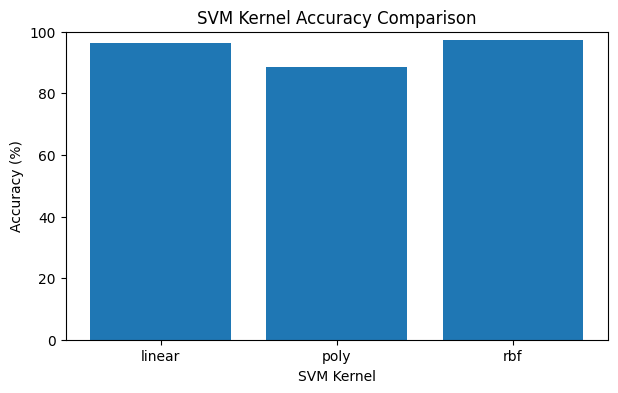

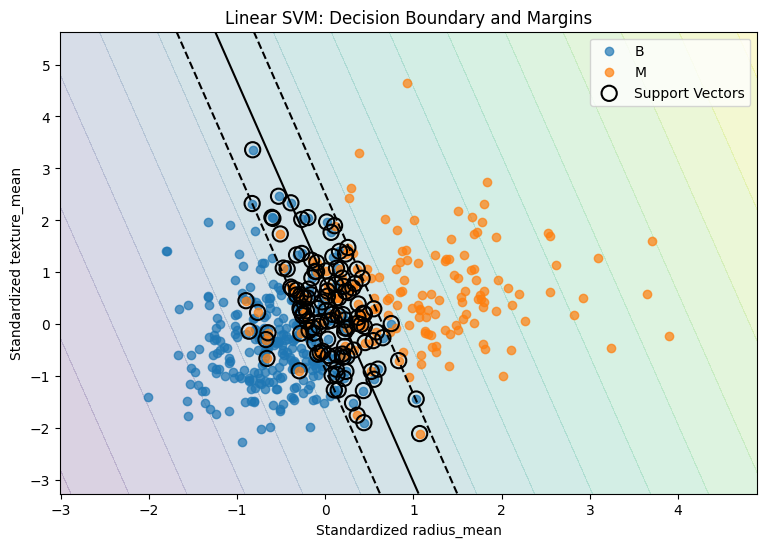

Number of support vectors: 125

Best parameters:
{'svm__C': 1, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}

Best cross-validation accuracy: 97.36 %

Best model test accuracy: 97.37 %

Classification Report:
              precision    recall  f1-score   support

           B       0.96      1.00      0.98        72
           M       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



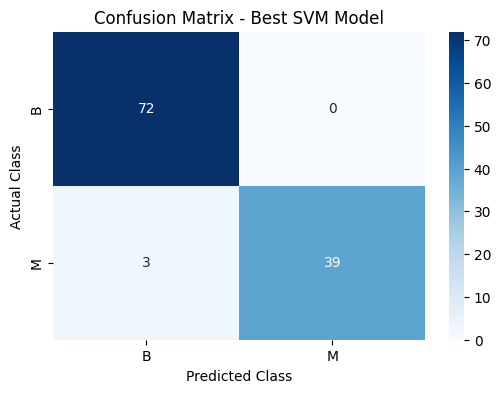

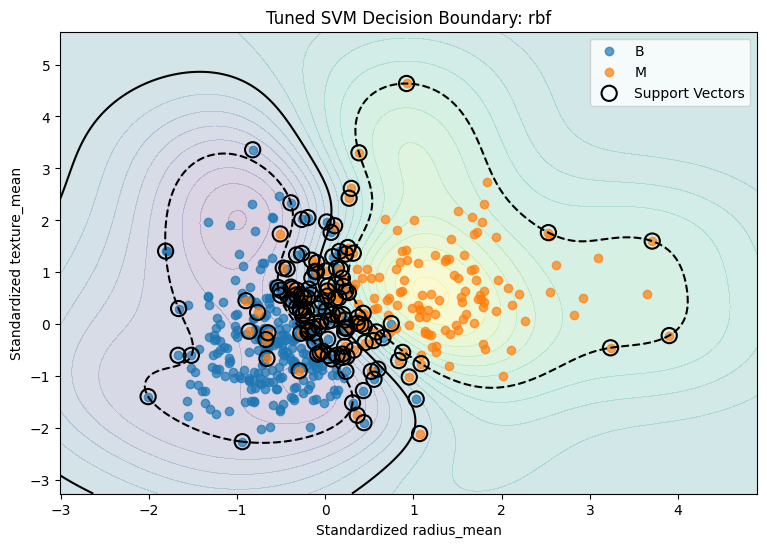


Experiment completed successfully!


In [1]:

# EXPERIMENT 6: SUPPORT VECTOR MACHINES (SVM)
# Objective: Apply SVM with different kernels and analyze decision boundaries.

# STEP 1: Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# STEP 2: Upload Kaggle dataset

uploaded = files.upload()
filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print(df.head())
print("Dataset shape:", df.shape)

# STEP 3: Preprocess data

df = df.drop(columns=["id", "Unnamed: 32"], errors="ignore")
df = df.dropna()

X = df.drop("diagnosis", axis=1)
y = df["diagnosis"]

print("\nClass distribution:")
print(y.value_counts())

# STEP 4: Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# STEP 5: Train SVM using Linear, Polynomial and RBF kernels

kernels = ["linear", "poly", "rbf"]
models = {}
results = {}

for kernel in kernels:

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel=kernel, C=1, gamma="scale"))
    ])

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)

    models[kernel] = model
    results[kernel] = accuracy * 100

    print("\nKernel:", kernel)
    print("Accuracy:", round(accuracy * 100, 2), "%")

# STEP 6: Compare kernel accuracies

plt.figure(figsize=(7, 4))
plt.bar(results.keys(), results.values())
plt.xlabel("SVM Kernel")
plt.ylabel("Accuracy (%)")
plt.title("SVM Kernel Accuracy Comparison")
plt.ylim(0, 100)
plt.show()

# STEP 7: Visualize decision boundary, margins and support vectors
# Use two features so the graph can be plotted in 2D.

features = ["radius_mean", "texture_mean"]
X_2d = df[features]
y_2d = df["diagnosis"]

X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d, y_2d,
    test_size=0.2,
    random_state=42,
    stratify=y_2d
)

scaler_2d = StandardScaler()
X_train_scaled = scaler_2d.fit_transform(X_train_2d)

svm_2d = SVC(kernel="linear", C=1)
svm_2d.fit(X_train_scaled, y_train_2d)

# Create mesh grid

x_min = X_train_scaled[:, 0].min() - 1
x_max = X_train_scaled[:, 0].max() + 1
y_min = X_train_scaled[:, 1].min() - 1
y_max = X_train_scaled[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

Z = svm_2d.decision_function(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(9, 6))

plt.contourf(xx, yy, Z, levels=20, alpha=0.2)
plt.contour(
    xx, yy, Z,
    levels=[-1, 0, 1],
    colors="black",
    linestyles=["--", "-", "--"]
)

for label in np.unique(y_train_2d):
    mask = y_train_2d.to_numpy() == label
    plt.scatter(
        X_train_scaled[mask, 0],
        X_train_scaled[mask, 1],
        label=label,
        alpha=0.7
    )

# Highlight support vectors

plt.scatter(
    svm_2d.support_vectors_[:, 0],
    svm_2d.support_vectors_[:, 1],
    s=120,
    facecolors="none",
    edgecolors="black",
    linewidths=1.5,
    label="Support Vectors"
)

plt.xlabel("Standardized radius_mean")
plt.ylabel("Standardized texture_mean")
plt.title("Linear SVM: Decision Boundary and Margins")
plt.legend()
plt.show()

print("Number of support vectors:",
      len(svm_2d.support_vectors_))

# STEP 8: Hyperparameter tuning using GridSearchCV

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC())
])

param_grid = [
    {
        "svm__kernel": ["linear"],
        "svm__C": [0.1, 1, 10, 100]
    },
    {
        "svm__kernel": ["poly"],
        "svm__C": [0.1, 1, 10],
        "svm__gamma": ["scale", 0.01, 0.1],
        "svm__degree": [2, 3]
    },
    {
        "svm__kernel": ["rbf"],
        "svm__C": [0.1, 1, 10, 100],
        "svm__gamma": ["scale", 0.001, 0.01, 0.1]
    }
]

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("\nBest parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation accuracy:",
      round(grid_search.best_score_ * 100, 2), "%")

# STEP 9: Evaluate best model on test data

best_model = grid_search.best_estimator_
y_pred_best = best_model.predict(X_test)

print("\nBest model test accuracy:",
      round(accuracy_score(y_test, y_pred_best) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_best))

# STEP 10: Confusion matrix

cm = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=best_model.classes_,
    yticklabels=best_model.classes_
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix - Best SVM Model")
plt.show()

# STEP 11: Visualize tuned kernel using two features

best_svm = best_model.named_steps["svm"]

visual_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(
        kernel=best_svm.kernel,
        C=best_svm.C,
        gamma=best_svm.gamma,
        degree=best_svm.degree
    ))
])

visual_model.fit(X_train_2d, y_train_2d)

visual_scaler = visual_model.named_steps["scaler"]
visual_svm = visual_model.named_steps["svm"]

X_scaled = visual_scaler.transform(X_train_2d)

x_min, x_max = X_scaled[:, 0].min() - 1, X_scaled[:, 0].max() + 1
y_min, y_max = X_scaled[:, 1].min() - 1, X_scaled[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 250),
    np.linspace(y_min, y_max, 250)
)

Z = visual_svm.decision_function(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(9, 6))
plt.contourf(xx, yy, Z, levels=20, alpha=0.2)
plt.contour(
    xx, yy, Z,
    levels=[-1, 0, 1],
    colors="black",
    linestyles=["--", "-", "--"]
)

for label in np.unique(y_train_2d):
    mask = y_train_2d.to_numpy() == label
    plt.scatter(
        X_scaled[mask, 0],
        X_scaled[mask, 1],
        label=label,
        alpha=0.7
    )

plt.scatter(
    visual_svm.support_vectors_[:, 0],
    visual_svm.support_vectors_[:, 1],
    s=120,
    facecolors="none",
    edgecolors="black",
    linewidths=1.5,
    label="Support Vectors"
)

plt.xlabel("Standardized radius_mean")
plt.ylabel("Standardized texture_mean")
plt.title("Tuned SVM Decision Boundary: " + best_svm.kernel)
plt.legend()
plt.show()

print("\nExperiment completed successfully!")
